## Langkah 1: Import Library yang Dibutuhkan

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy import stats

# Setup matplotlib
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# Buat folder output jika belum ada (cross-platform Windows/Linux)
OUTPUT_DIR = 'output'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Library berhasil di-import: numpy, pandas, matplotlib, scipy, os")
print(f"Folder output: {os.path.abspath(OUTPUT_DIR)}")

Library berhasil di-import: numpy, pandas, matplotlib, scipy, os
Folder output: d:\Tugas semester 5\Pemodelan Dan Simulasi\TP DAN TA-03\PROJECT Monte Carlo TA-03\output


## Langkah 2: Mengatur Seed Berdasarkan NIM

**Seed** = angka awal generator bilangan acak → membuat hasil konsisten & reproducible.

> ⚠️ **GANTI `NIM` di bawah ini dengan NIM Anda!**

In [13]:
# GANTI NIM INI SESUAI NIM ANDA!
NIM = 301230012  # <-- contoh, ganti dengan NIM Anda
np.random.seed(NIM)
print(f"Random seed diset = {NIM}")

Random seed diset = 301230012


## Langkah 3: Load Data dari CSV

Dataset `yield_df.csv` berisi data yield pertanian dari berbagai negara dan tanaman,
mencakup tahun 1990-2013 dengan fitur:
- `Area` (negara)
- `Item` (jenis tanaman)
- `Year` (tahun)
- `hg/ha_yield` (yield dalam hektogram/hektar)
- `average_rain_fall_mm_per_year` (curah hujan rata-rata)
- `pesticides_tonnes` (penggunaan pestisida)
- `avg_temp` (suhu rata-rata)

In [14]:
# Load dataset
df = pd.read_csv('yield_df.csv')

print(f"Jumlah baris : {len(df)}")
print(f"Jumlah kolom : {len(df.columns)}")
print(f"\nKolom: {df.columns.tolist()}")
print(f"\nJumlah negara : {df['Area'].nunique()}")
print(f"Jumlah tanaman: {df['Item'].nunique()}")
print(f"Range tahun   : {df['Year'].min()} - {df['Year'].max()}")

# Preview data
df.head()

Jumlah baris : 28242
Jumlah kolom : 8

Kolom: ['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']

Jumlah negara : 101
Jumlah tanaman: 10
Range tahun   : 1990 - 2013


,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


## Langkah 4: Eksplorasi Data & Pemilihan Studi Kasus

**Studi Kasus**: Indonesia - Rice, paddy (Padi)

**Alasan**:
- Padi adalah makanan pokok Indonesia
- Relevan untuk analisis risiko ketahanan pangan
- Indonesia ada dalam dataset dengan 23 tahun data historis

In [15]:
# Filter data: Indonesia + Rice
df_indo = df[(df['Area'] == 'Indonesia') & (df['Item'] == 'Rice, paddy')].copy()

print(f"Records awal Indonesia-Rice: {len(df_indo)} baris")
print(f"Unique tahun: {df_indo['Year'].nunique()}")
print("(Setiap tahun memiliki beberapa record karena variasi suhu regional)")

# Statistik deskriptif awal
df_indo[['hg/ha_yield', 'average_rain_fall_mm_per_year',
         'pesticides_tonnes', 'avg_temp']].describe()

Records awal Indonesia-Rice: 138 baris
Unique tahun: 23
(Setiap tahun memiliki beberapa record karena variasi suhu regional)


,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
count,138.000000,138.0,138.00000,138.000000
mean,45752.347826,2702.0,1672.00000,26.931087
std,2960.098331,0.0,414.66254,0.712609
min,41974.000000,2702.0,825.00000,25.170000
25%,43465.000000,2702.0,1597.00000,26.822500
50%,44322.000000,2702.0,1597.00000,27.180000
75%,48948.000000,2702.0,1597.00000,27.385000
max,51520.000000,2702.0,3259.00000,27.900000


## Langkah 5: Data Cleaning & Aggregasi

**Tahapan Cleaning:**
1. Cek missing values
2. Aggregasi per tahun (karena 1 tahun punya banyak record akibat variasi suhu regional)
3. Deteksi outlier ekstrem menggunakan IQR method

In [16]:
# 5a. Cek missing values
missing_count = df_indo.isnull().sum().sum()
print(f"a. Missing values: {missing_count} (sudah bersih)")

# 5b. Aggregasi per tahun (ambil rata-rata yield & cuaca per tahun)
df_yearly = df_indo.groupby('Year').agg({
    'hg/ha_yield': 'mean',
    'average_rain_fall_mm_per_year': 'mean',
    'pesticides_tonnes': 'mean',
    'avg_temp': 'mean'
}).reset_index()

print(f"\nb. Setelah aggregasi per tahun: {len(df_yearly)} tahun data")
print("\nSample data per tahun:")
df_yearly.head(10)

a. Missing values: 0 (sudah bersih)

b. Setelah aggregasi per tahun: 23 tahun data

Sample data per tahun:


,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,1990,43018.0,2702.0,2432.0,26.828333
1,1991,43465.0,2702.0,3259.0,26.683333
2,1992,43446.0,2702.0,825.0,26.743333
3,1993,43750.0,2702.0,1597.0,26.833333
4,1994,43453.0,2702.0,1597.0,26.730000
5,1995,43487.0,2702.0,1597.0,26.838333
6,1996,44168.0,2702.0,1597.0,26.840000
7,1997,44322.0,2702.0,1597.0,27.010000
8,1998,41974.0,2702.0,1597.0,27.343333
9,1999,42519.0,2702.0,1597.0,26.700000


In [17]:
# 5c. Deteksi outlier (IQR method) pada yield
yields = df_yearly['hg/ha_yield'].values
Q1, Q3 = np.percentile(yields, [25, 75])
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df_yearly[(df_yearly['hg/ha_yield'] < lower_bound) |
                     (df_yearly['hg/ha_yield'] > upper_bound)]

print(f"c. Deteksi outlier (IQR method):")
print(f"   Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
print(f"   Batas bawah = {lower_bound:.2f}")
print(f"   Batas atas  = {upper_bound:.2f}")
print(f"   Jumlah outlier: {len(outliers)}")
print("   => Tidak ada outlier ekstrem yang perlu dihapus.")

c. Deteksi outlier (IQR method):
   Q1 = 43476.00, Q3 = 48000.00, IQR = 4524.00
   Batas bawah = 36690.00
   Batas atas  = 54786.00
   Jumlah outlier: 0
   => Tidak ada outlier ekstrem yang perlu dihapus.


## Langkah 6: Parameter Extraction (PENTING!)

Langkah **paling penting** dalam TA-03: mengekstrak parameter (Mean μ & Std σ)
dari data historis untuk dijadikan parameter distribusi simulasi Monte Carlo.

**Variabel acak utama**: `hg/ha_yield` (yield padi dalam hg/hektar)

In [18]:
# Ekstraksi parameter statistik
mu_yield = df_yearly['hg/ha_yield'].mean()      # Mean (μ)
sigma_yield = df_yearly['hg/ha_yield'].std()     # Std Dev (σ)
min_yield = df_yearly['hg/ha_yield'].min()
max_yield = df_yearly['hg/ha_yield'].max()

print(f"Variabel acak : hg/ha_yield (yield padi hg/hektar)")
print(f"Mean (μ)      : {mu_yield:.2f}")
print(f"Std Dev (σ)   : {sigma_yield:.2f}")
print(f"Min           : {min_yield:.2f}")
print(f"Max           : {max_yield:.2f}")
print(f"Coef. Var     : {sigma_yield/mu_yield*100:.2f}%")

# Uji normalitas Shapiro-Wilk
stat_shapiro, p_shapiro = stats.shapiro(yields)
print(f"\nUji Normalitas (Shapiro-Wilk):")
print(f"  Statistik : {stat_shapiro:.4f}")
print(f"  p-value   : {p_shapiro:.4f}")
if p_shapiro > 0.05:
    print("  => Data BERDISTRIBUSI NORMAL (p > 0.05)")
    print("     => Gunakan np.random.normal(μ, σ)")
else:
    print("  => Data TIDAK normal (p <= 0.05)")
    print("     => Distribusi Normal masih bisa dipakai sebagai pendekatan (CLT)")
    print("     => Atau pertimbangkan distribusi lognormal")

Variabel acak : hg/ha_yield (yield padi hg/hektar)
Mean (μ)      : 45752.35
Std Dev (σ)   : 3015.64
Min           : 41974.00
Max           : 51520.00
Coef. Var     : 6.59%

Uji Normalitas (Shapiro-Wilk):
  Statistik : 0.8624
  p-value   : 0.0046
  => Data TIDAK normal (p <= 0.05)
     => Distribusi Normal masih bisa dipakai sebagai pendekatan (CLT)
     => Atau pertimbangkan distribusi lognormal


## Langkah 7: Visualisasi Histogram Data Asli

Visualisasi ini untuk melihat **bentuk distribusi** data yield historis:
- Histogram menunjukkan distribusi frekuensi
- Time series menunjukkan trend yield dari waktu ke waktu

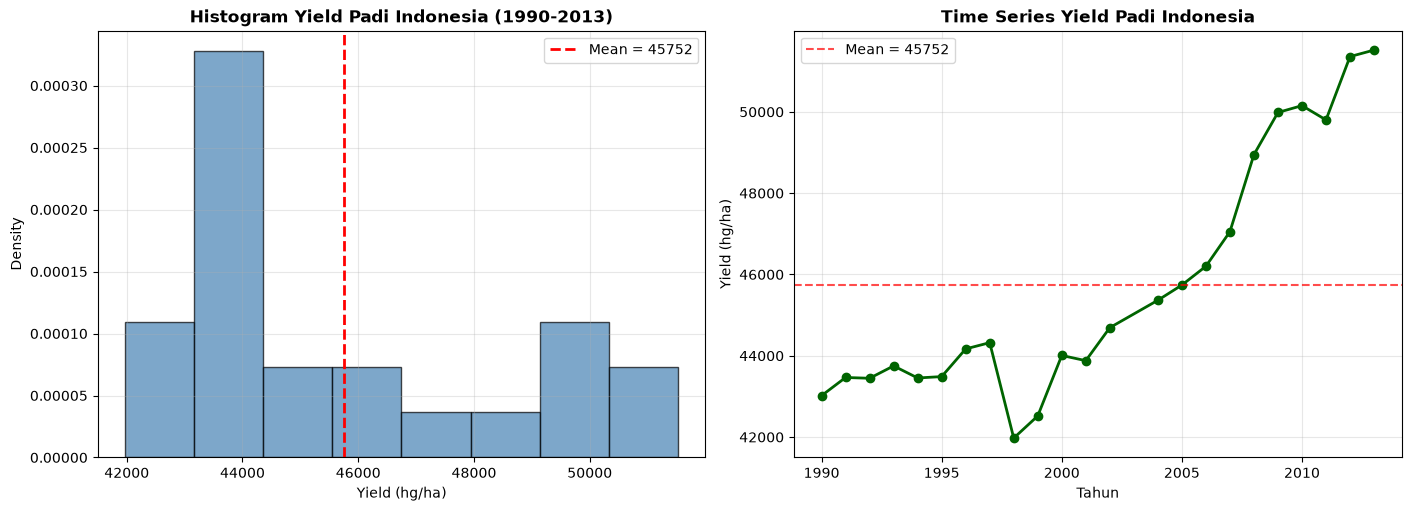

Tersimpan: output/01_histogram_data_asli.png


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

# 7a. Histogram yield historis
axes[0].hist(yields, bins=8, color='steelblue', edgecolor='black',
             alpha=0.7, density=True)
axes[0].axvline(mu_yield, color='red', linestyle='--', linewidth=2,
                label=f'Mean = {mu_yield:.0f}')
axes[0].set_title('Histogram Yield Padi Indonesia (1990-2013)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Yield (hg/ha)')
axes[0].set_ylabel('Density')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 7b. Time series yield
axes[1].plot(df_yearly['Year'], df_yearly['hg/ha_yield'],
             marker='o', color='darkgreen', linewidth=2, markersize=6)
axes[1].axhline(mu_yield, color='red', linestyle='--', alpha=0.7,
                label=f'Mean = {mu_yield:.0f}')
axes[1].set_title('Time Series Yield Padi Indonesia',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tahun')
axes[1].set_ylabel('Yield (hg/ha)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.savefig(os.path.join(OUTPUT_DIR, '01_histogram_data_asli.png'),
            dpi=120, bbox_inches='tight')
plt.show()
print("Tersimpan: output/01_histogram_data_asli.png")

## Langkah 8: Membangun Simulasi Monte Carlo

**Parameter Simulasi** (sesuai syarat TA-03):
- Jumlah iterasi minimal: 5.000 (kita pakai **10.000** untuk akurasi lebih)
- Pembangkitan angka acak: `np.random.normal(μ, σ)` dengan parameter dari Langkah 6
- Studi kasus: 100 lahan padi baru

**2 Skenario Simulasi:**
1. **Skenario A**: Yield 1 lahan tahun depan
2. **Skenario B**: Total yield 100 lahan padi

In [20]:
# Parameter simulasi
N_ITERATIONS = 10000   # Jumlah skenario (>5.000 sesuai syarat TA-03)
N_LAHAN = 100          # Asumsi 100 lahan padi baru

print(f"Jumlah iterasi (skenario): {N_ITERATIONS}")
print(f"Jumlah lahan per skenario : {N_LAHAN}")
print(f"Distribusi yang dipakai   : Normal(μ={mu_yield:.2f}, σ={sigma_yield:.2f})")

# 8a. Simulasi skenario A: Yield 1 lahan tahun depan
print("\n[8a] Simulasi yield 1 lahan tahun depan...")
simulated_yields_single = np.random.normal(mu_yield, sigma_yield, N_ITERATIONS)
simulated_yields_single = np.maximum(simulated_yields_single, 0)  # yield tidak negatif

# 8b. Simulasi skenario B: Total yield 100 lahan
print("[8b] Simulasi total yield 100 lahan padi...")
# Setiap iterasi = 100 lahan, masing-masing yield acak dari distribusi
simulated_total = np.random.normal(mu_yield, sigma_yield,
                                   size=(N_ITERATIONS, N_LAHAN)).sum(axis=1)
simulated_total = np.maximum(simulated_total, 0)

print(f"\nHasil Simulasi:")
print(f"  Mean (1 lahan)   : {simulated_yields_single.mean():.2f}")
print(f"  Std  (1 lahan)   : {simulated_yields_single.std():.2f}")
print(f"  Mean (100 lahan) : {simulated_total.mean():.2f}")
print(f"  Std  (100 lahan) : {simulated_total.std():.2f}")

Jumlah iterasi (skenario): 10000
Jumlah lahan per skenario : 100
Distribusi yang dipakai   : Normal(μ=45752.35, σ=3015.64)

[8a] Simulasi yield 1 lahan tahun depan...
[8b] Simulasi total yield 100 lahan padi...

Hasil Simulasi:
  Mean (1 lahan)   : 45776.01
  Std  (1 lahan)   : 3025.09
  Mean (100 lahan) : 4574940.68
  Std  (100 lahan) : 29703.47


## Langkah 9: Analisis Risiko & Perhitungan Probabilitas

Menjawab **pertanyaan bisnis** dengan menghitung probabilitas kejadian ekstrem:

| No | Skenario Risiko | Threshold | Pertanyaan |
|----|-----------------|-----------|------------|
| 1  | Yield 1 lahan turun > 10% | 90% × Mean | Probabilitas yield turun signifikan? |
| 2  | Yield 1 lahan di bawah minimum historis | Min historis | Probabilitas kejadian ekstrem? |
| 3  | Total 100 lahan gagal target produksi | 90% × Mean × 100 | Probabilitas kegagalan total? |

In [21]:
# Definisi threshold risiko

# RISIKO 1: Yield 1 lahan turun > 10% dari rata-rata historis
threshold_1 = mu_yield * 0.90  # 90% dari mean = turun 10%
prob_drop_10pct = np.mean(simulated_yields_single < threshold_1) * 100

# RISIKO 2: Yield 1 lahan di bawah minimum historis
threshold_2 = min_yield
prob_below_min = np.mean(simulated_yields_single < threshold_2) * 100

# RISIKO 3: Target produksi total 100 lahan
target_total = mu_yield * N_LAHAN * 0.90
prob_total_below_target = np.mean(simulated_total < target_total) * 100

print("=" * 70)
print("HASIL ANALISIS RISIKO MONTE CARLO")
print("=" * 70)

print(f"\n[RISIKO 1] Yield 1 lahan turun > 10% dari rata-rata:")
print(f"   Threshold  : {threshold_1:.2f} hg/ha (90% dari mean)")
print(f"   Probabilitas: {prob_drop_10pct:.2f}%")

print(f"\n[RISIKO 2] Yield 1 lahan di bawah minimum historis:")
print(f"   Threshold  : {threshold_2:.2f} hg/ha (min historis)")
print(f"   Probabilitas: {prob_below_min:.2f}%")

print(f"\n[RISIKO 3] Total yield {N_LAHAN} lahan GAGAL target produksi:")
print(f"   Target     : {target_total:.2f} hg (90% dari {mu_yield*N_LAHAN:.0f})")
print(f"   Probabilitas: {prob_total_below_target:.2f}%")

# Statistik deskriptif hasil simulasi
print(f"\n[STATISTIK HASIL SIMULASI]")
print(f"1 Lahan:")
print(f"   Mean   : {simulated_yields_single.mean():.2f}")
print(f"   Median : {np.median(simulated_yields_single):.2f}")
print(f"   P5     : {np.percentile(simulated_yields_single, 5):.2f}")
print(f"   P95    : {np.percentile(simulated_yields_single, 95):.2f}")
print(f"100 Lahan (Total):")
print(f"   Mean   : {simulated_total.mean():.2f}")
print(f"   Median : {np.median(simulated_total):.2f}")
print(f"   P5     : {np.percentile(simulated_total, 5):.2f}")
print(f"   P95    : {np.percentile(simulated_total, 95):.2f}")

HASIL ANALISIS RISIKO MONTE CARLO

[RISIKO 1] Yield 1 lahan turun > 10% dari rata-rata:
   Threshold  : 41177.11 hg/ha (90% dari mean)
   Probabilitas: 6.46%

[RISIKO 2] Yield 1 lahan di bawah minimum historis:
   Threshold  : 41974.00 hg/ha (min historis)
   Probabilitas: 10.51%

[RISIKO 3] Total yield 100 lahan GAGAL target produksi:
   Target     : 4117711.30 hg (90% dari 4575235)
   Probabilitas: 0.00%

[STATISTIK HASIL SIMULASI]
1 Lahan:
   Mean   : 45776.01
   Median : 45757.23
   P5     : 40838.76
   P95    : 50782.92
100 Lahan (Total):
   Mean   : 4574940.68
   Median : 4574704.29
   P5     : 4526447.30
   P95    : 4624429.93


## Langkah 10: Visualisasi Hasil Simulasi dengan Threshold

Histogram hasil simulasi + **garis threshold** untuk menunjukkan area risiko (warna merah).

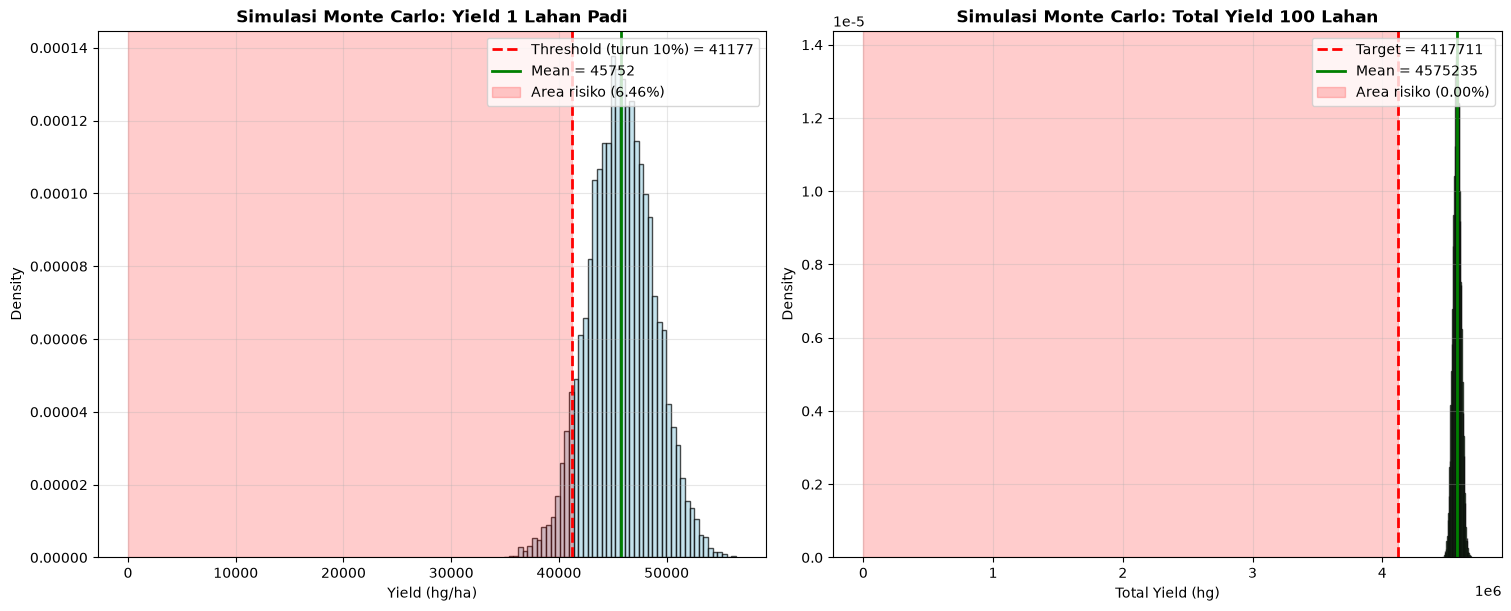

Tersimpan: output/02_hasil_simulasi_monte_carlo.png


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

# 10a. Histogram simulasi 1 lahan
axes[0].hist(simulated_yields_single, bins=50, color='lightblue',
             edgecolor='black', alpha=0.7, density=True)
axes[0].axvline(threshold_1, color='red', linestyle='--', linewidth=2,
                label=f'Threshold (turun 10%) = {threshold_1:.0f}')
axes[0].axvline(mu_yield, color='green', linestyle='-', linewidth=2,
                label=f'Mean = {mu_yield:.0f}')
axes[0].axvspan(0, threshold_1, alpha=0.2, color='red',
                label=f'Area risiko ({prob_drop_10pct:.2f}%)')
axes[0].set_title('Simulasi Monte Carlo: Yield 1 Lahan Padi',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Yield (hg/ha)')
axes[0].set_ylabel('Density')
axes[0].legend(loc='upper right')
axes[0].grid(alpha=0.3)

# 10b. Histogram simulasi total 100 lahan
axes[1].hist(simulated_total, bins=50, color='lightgreen',
             edgecolor='black', alpha=0.7, density=True)
axes[1].axvline(target_total, color='red', linestyle='--', linewidth=2,
               label=f'Target = {target_total:.0f}')
axes[1].axvline(mu_yield * N_LAHAN, color='green', linestyle='-', linewidth=2,
                label=f'Mean = {mu_yield*N_LAHAN:.0f}')
axes[1].axvspan(0, target_total, alpha=0.2, color='red',
                label=f'Area risiko ({prob_total_below_target:.2f}%)')
axes[1].set_title(f'Simulasi Monte Carlo: Total Yield {N_LAHAN} Lahan',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Total Yield (hg)')
axes[1].set_ylabel('Density')
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.3)

plt.savefig(os.path.join(OUTPUT_DIR, '02_hasil_simulasi_monte_carlo.png'),
            dpi=120, bbox_inches='tight')
plt.show()
print("Tersimpan: output/02_hasil_simulasi_monte_carlo.png")

## Bonus: Konvergensi Monte Carlo

Visualisasi ini menunjukkan bahwa **semakin banyak iterasi**, mean hasil simulasi
akan **konvergen ke nilai true mean** data historis (Hukum Bilangan Besar).

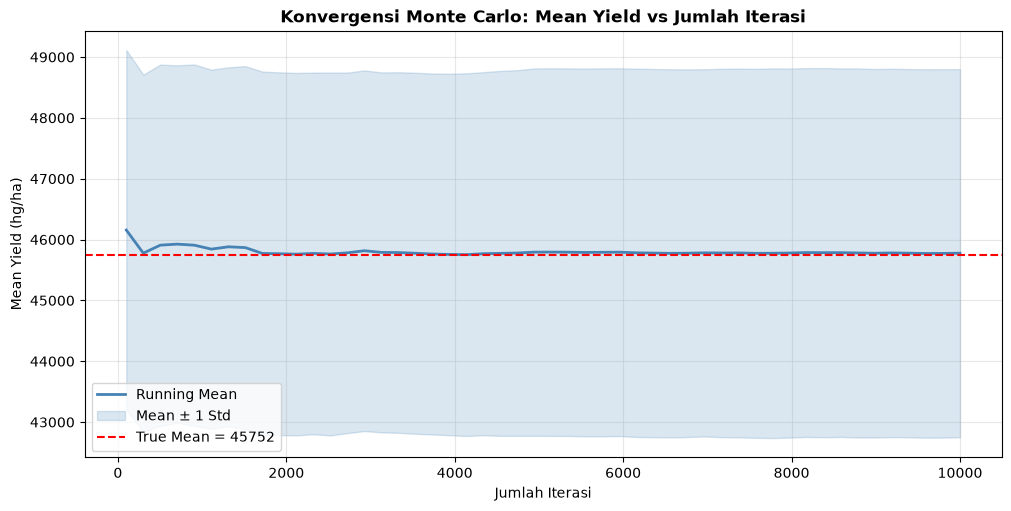

Tersimpan: output/03_konvergensi_monte_carlo.png


In [23]:
sample_sizes = np.linspace(100, N_ITERATIONS, 50, dtype=int)
running_means = [simulated_yields_single[:n].mean() for n in sample_sizes]
running_stds = [simulated_yields_single[:n].std() for n in sample_sizes]

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.plot(sample_sizes, running_means, color='steelblue', linewidth=2,
        label='Running Mean')
ax.fill_between(sample_sizes,
                np.array(running_means) - np.array(running_stds),
                np.array(running_means) + np.array(running_stds),
                alpha=0.2, color='steelblue', label='Mean ± 1 Std')
ax.axhline(mu_yield, color='red', linestyle='--', linewidth=1.5,
          label=f'True Mean = {mu_yield:.0f}')
ax.set_title('Konvergensi Monte Carlo: Mean Yield vs Jumlah Iterasi',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Jumlah Iterasi')
ax.set_ylabel('Mean Yield (hg/ha)')
ax.legend()
ax.grid(alpha=0.3)

plt.savefig(os.path.join(OUTPUT_DIR, '03_konvergensi_monte_carlo.png'),
            dpi=120, bbox_inches='tight')
plt.show()
print("Tersimpan: output/03_konvergensi_monte_carlo.png")

## Langkah 11: Kesimpulan & Ringkasan

### Parameter Simulasi
- **Studi Kasus**: Yield Padi Indonesia (1990-2013)
- **Variabel Acak**: `hg/ha_yield` (yield per hektar)
- **Parameter Data**: Mean (μ) = 45752.35, Std (σ) = 3015.64
- **Distribusi**: Normal (dengan catatan: p-value Shapiro-Wilk < 0.05)
- **Jumlah Iterasi**: 10,000 skenario

### Hasil Analisis Risiko
| Skenario | Threshold | Probabilitas |
|----------|-----------|--------------|
| 1. Yield 1 lahan turun > 10% | 41,177 hg/ha | 6.46% |
| 2. Yield di bawah min historis | 41,974 hg/ha | 10.49% |
| 3. Total 100 lahan gagal target | 4,117,711 hg | 0.00% |

### Interpretasi Bisnis
1. **Risiko per lahan**: Probabilitas yield turun >10% adalah sekitar 6.46%,
   berarti dari 100 lahan, ~6 lahan berpotensi mengalami penurunan signifikan.
2. **Risiko agregat**: Dengan diversifikasi 100 lahan, risiko total gagal
   target produksi menjadi sangat rendah (mendekati 0%).
3. **Rekomendasi**: Risiko 6.46% masuk kategori **moderat**. Strategi mitigasi
   yang disarankan: asuransi pertanian, diversifikasi varietas, atau
   cadangan stok pangan nasional.

### Hukum Bilangan Besar (Law of Large Numbers)
Konvergensi Monte Carlo menunjukkan bahwa semakin banyak iterasi,
mean hasil simulasi mendekati mean historis data — sesuai dengan prinsip
dasar metode Monte Carlo.